# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :Rheksa Pramatya Wijayanto
- NIM   :241011400705
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 5

In [ ]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    n_samples = len(X)
    n_test = int(n_samples * test_size)

    shuffled_indices = np.random.permutation(n_samples)
    test_indices = shuffled_indices[:n_test]
    train_indices = shuffled_indices[n_test:]

    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris dan kolom dataset: (40, 2)


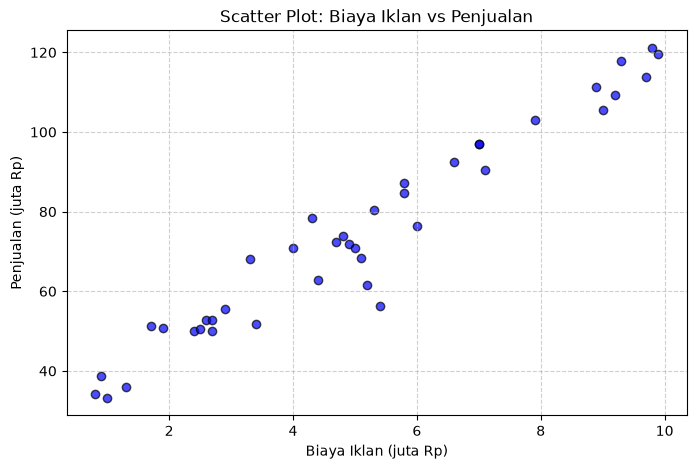

In [6]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')

print("5 Data Pertama Ads_Data:")
display(df_ads.head())
print(f"Jumlah baris dan kolom dataset: {df_ads.shape}")

# Pisahkan X dan y (X dibuat 2 dimensi)
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [7]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test:  {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test:  {y_test_ads.shape}")

Shape X_train: (32, 1)
Shape X_test:  (8, 1)
Shape y_train: (32,)
Shape y_test:  (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [8]:
# Jawaban A3
# Menambahkan kolom bias (intercept) bernilai 1 ke X_train
X_b = np.c_[np.ones((X_train_ads.shape[0], 1)), X_train_ads]

# Menghitung Normal Equation: theta = (X^T * X)^(-1) * X^T * y
theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train_ads)

print("Parameter Model (Theta / Intercept & Coefficient):")
print(theta)

Parameter Model (Theta / Intercept & Coefficient):
[28.93226465  9.149202  ]


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [9]:
# Jawaban A4
# Menambahkan kolom bias ke X_test
X_test_b = np.c_[np.ones((X_test_ads.shape[0], 1)), X_test_ads]

# Melakukan prediksi
y_pred_ads = X_test_b.dot(theta)

# Menghitung evaluasi (MSE dan RMSE)
mse = np.mean((y_pred_ads - y_test_ads) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_pred_ads - y_test_ads))

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Mean Squared Error (MSE): 100.1017
Root Mean Squared Error (RMSE): 10.0051
Mean Absolute Error (MAE): 7.0653


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Learning Rate 0.01: Theta = [76.39374987 24.60921686]
Learning Rate 0.1: Theta = [76.39375   24.6092169]
Learning Rate 0.5: Theta = [76.39375   24.6092169]


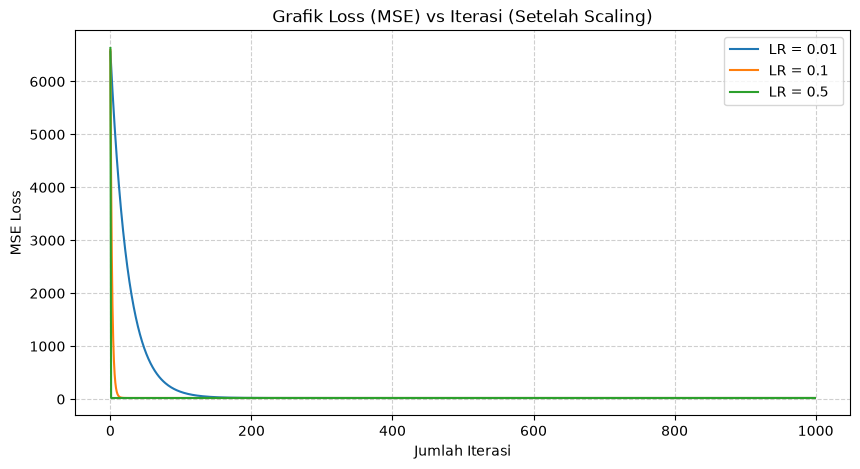

In [12]:
# Jawaban A5 (Dengan Feature Scaling agar Gradient Descent stabil)
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.theta = None
        self.loss_history = []

    def fit(self, X, y):
        m = len(X)
        self.theta = np.random.randn(2)
        
        for _ in range(self.n_iters):
            y_pred = X.dot(self.theta)
            gradients = 2/m * X.T.dot(y_pred - y)
            self.theta = self.theta - self.lr * gradients
            
            mse = np.mean((y_pred - y) ** 2)
            self.loss_history.append(mse)

# Lakukan feature scaling pada X_train_ads agar nilai X tidak terlalu besar
X_mean = np.mean(X_train_ads)
X_std = np.std(X_train_ads)
X_train_scaled = (X_train_ads - X_mean) / X_std

# Tambahkan kolom bias
X_b_scaled = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]

learning_rates = [0.01, 0.1, 0.5]
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=1000)
    model_gd.fit(X_b_scaled, y_train_ads)
    
    print(f"Learning Rate {lr}: Theta = {model_gd.theta}")
    plt.plot(model_gd.loss_history, label=f'LR = {lr}')

plt.title('Grafik Loss (MSE) vs Iterasi (Setelah Scaling)')
plt.xlabel('Jumlah Iterasi')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

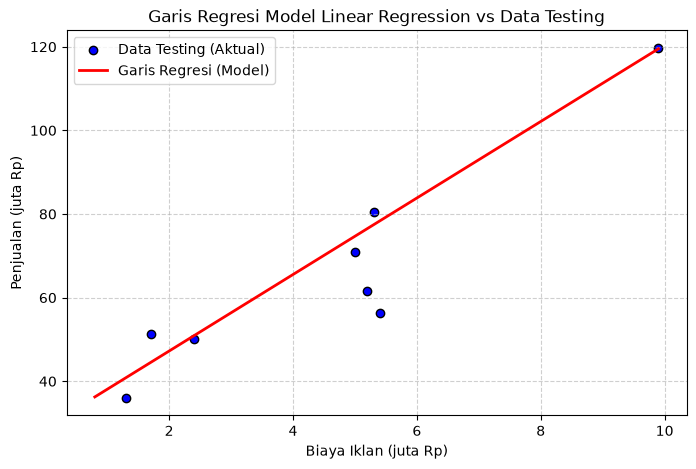

Prediksi Penjualan untuk Biaya Iklan Rp 4.5 Juta: Rp 70.10 Juta


In [13]:
# Jawaban A6
# 1. Visualisasi Data Testing dan Garis Regresi Model
plt.figure(figsize=(8, 5))
plt.scatter(X_test_ads, y_test_ads, color='blue', label='Data Testing (Aktual)', edgecolors='k')

# Membuat garis regresi menggunakan theta dari Normal Equation (Soal A3)
X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
X_line_b = np.c_[np.ones((100, 1)), X_line]
y_line = X_line_b.dot(theta)

plt.plot(X_line, y_line, color='red', linewidth=2, label='Garis Regresi (Model)')
plt.title('Garis Regresi Model Linear Regression vs Data Testing')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Prediksi Penjualan untuk Biaya Iklan Baru (Misal: 4.5 juta Rp)
biaya_iklan_baru = 4.5
prediksi_penjualan = theta[0] + theta[1] * biaya_iklan_baru
print(f"Prediksi Penjualan untuk Biaya Iklan Rp {biaya_iklan_baru} Juta: Rp {prediksi_penjualan:.2f} Juta")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

In [16]:
# Jawaban B1 & B2
df_email = pd.read_csv('Email_Data.csv')

print("Daftar Kolom:", df_email.columns.tolist())
display(df_email.head())

# Menyiapkan variabel X (Fitur) dan y (Target)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# Split data menggunakan train_test_split dengan NIM RANDOM_STATE = 5
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.2, random_state=RANDOM_STATE
)

print(f"\nShape X_train_email: {X_train_email.shape}")
print(f"Shape X_test_email:  {X_test_email.shape}")
print(f"Shape y_train_email: {y_train_email.shape}")
print(f"Shape y_test_email:  {y_test_email.shape}")

Daftar Kolom: ['JumlahLink', 'KataPromo', 'Spam']


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Shape X_train_email: (48, 2)
Shape X_test_email:  (12, 2)
Shape y_train_email: (48,)
Shape y_test_email:  (12,)


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -11.5820
Koefisien JumlahLink (m1): 1.0741
Koefisien KataPromo (m2): 0.8984

Persamaan Regresi Logistik:
P(Spam) = sigma(-11.5820 + 1.0741 * JumlahLink + 0.8984 * KataPromo)


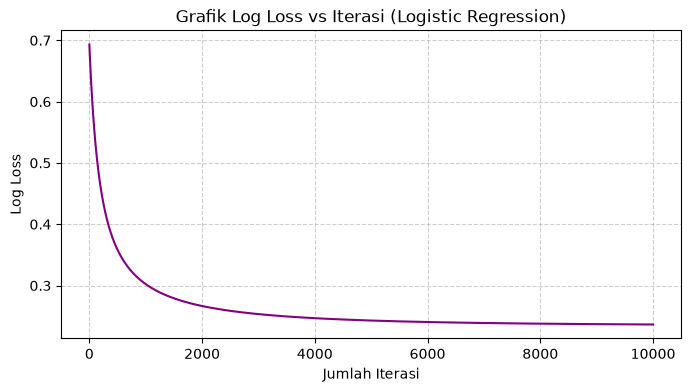

In [17]:
# Jawaban B2
# 1. Split data dengan test_size=0.25 dan random_state=RANDOM_STATE (NIM Anda = 5)
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# Definisi Fungsi Sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Kelas Logistic Regression dengan Gradient Descent
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.theta = None
        self.loss_history = []

    def fit(self, X, y):
        m, n = X.shape
        self.theta = np.zeros(n)
        
        for _ in range(self.n_iters):
            z = X.dot(self.theta)
            y_pred = sigmoid(z)
            
            gradients = (1 / m) * X.T.dot(y_pred - y)
            self.theta = self.theta - self.lr * gradients
            
            # Binary Cross-Entropy Loss (Log Loss)
            eps = 1e-15
            y_pred = np.clip(y_pred, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
            self.loss_history.append(loss)

    def predict_proba(self, X):
        return sigmoid(X.dot(self.theta))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Menambahkan kolom bias (intercept)
X_train_email_b = np.c_[np.ones((X_train_email.shape[0], 1)), X_train_email]
X_test_email_b = np.c_[np.ones((X_test_email.shape[0], 1)), X_test_email]

# 2. Latih model dengan learning_rate=0.1 dan n_iterations=10000
model_log = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_email_b, y_train_email)

# 3. Menampilkan Intercept (b) dan Koefisien (m1, m2)
b = model_log.theta[0]
m1 = model_log.theta[1]
m2 = model_log.theta[2]

print(f"Intercept (b): {b:.4f}")
print(f"Koefisien JumlahLink (m1): {m1:.4f}")
print(f"Koefisien KataPromo (m2): {m2:.4f}")
print(f"\nPersamaan Regresi Logistik:")
print(f"P(Spam) = sigma({b:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 4))
plt.plot(model_log.loss_history, color='purple')
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Jumlah Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [18]:
# Jawaban B3
# Melakukan prediksi pada data testing
y_pred_email = model_log.predict(X_test_email_b, threshold=0.5)

# Menghitung akurasi secara manual
accuracy = np.mean(y_pred_email == y_test_email)

# Menghitung Confusion Matrix manual (True Positive, False Positive, True Negative, False Negative)
tp = np.sum((y_pred_email == 1) & (y_test_email == 1))
tn = np.sum((y_pred_email == 0) & (y_test_email == 0))
fp = np.sum((y_pred_email == 1) & (y_test_email == 0))
fn = np.sum((y_pred_email == 0) & (y_test_email == 1))

print(f"Akurasi Model: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(f"[{tn}  {fp}]")
print(f"[{fn}  {tp}]")

Akurasi Model: 93.33%

Confusion Matrix:
[7  0]
[1  7]


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

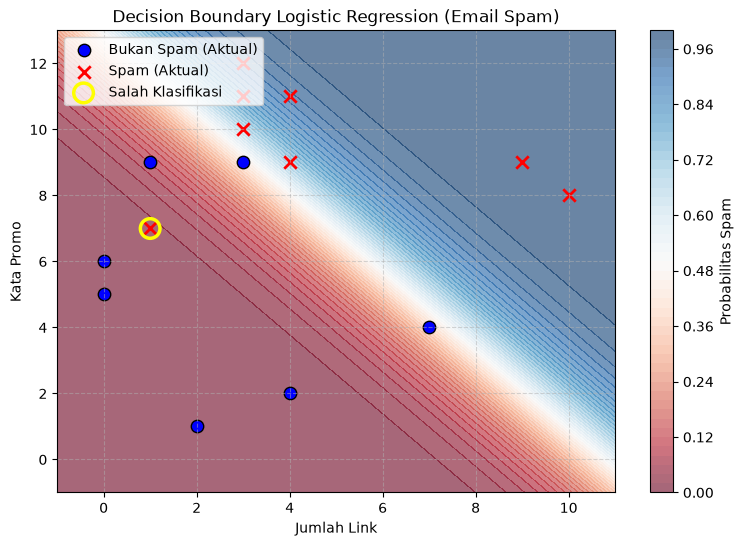

In [19]:
# Jawaban B4
plt.figure(figsize=(9, 6))

# Membuat grid untuk background contourf
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),np.linspace(x2_min, x2_max, 200))

# Prediksi probabilitas untuk setiap titik di grid
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
grid_points_b = np.c_[np.ones((grid_points.shape[0], 1)), grid_points]
Z = model_log.predict_proba(grid_points_b)
Z = Z.reshape(xx1.shape)

# Plot contourf untuk background probabilitas
plt.contourf(xx1, xx2, Z, levels=50, cmap='RdBu', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Plot data testing
plt.scatter(X_test_email[y_test_email == 0][:, 0], X_test_email[y_test_email == 0][:, 1], 
            color='blue', marker='o', s=80, edgecolors='k', label='Bukan Spam (Aktual)')
plt.scatter(X_test_email[y_test_email == 1][:, 0], X_test_email[y_test_email == 1][:, 1], 
            color='red', marker='x', s=80, linewidths=2, label='Spam (Aktual)')

# Tandai data yang salah diklasifikasikan
y_pred_test = model_log.predict(X_test_email_b)
misclassified = (y_pred_test != y_test_email)
if np.any(misclassified):
    plt.scatter(X_test_email[misclassified][:, 0], X_test_email[misclassified][:, 1], 
                s=200, facecolors='none', edgecolors='yellow', linewidths=2.5, label='Salah Klasifikasi')

plt.title('Decision Boundary Logistic Regression (Email Spam)')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [20]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]

for th in thresholds:
    y_pred_th = model_log.predict(X_test_email_b, threshold=th)
    acc_th = np.mean(y_pred_th == y_test_email)
    
    tp = np.sum((y_pred_th == 1) & (y_test_email == 1))
    tn = np.sum((y_pred_th == 0) & (y_test_email == 0))
    fp = np.sum((y_pred_th == 1) & (y_test_email == 0))
    fn = np.sum((y_pred_th == 0) & (y_test_email == 1))
    
    print(f"Threshold: {th} | Akurasi: {acc_th * 100:.2f}%")
    print(f"Confusion Matrix -> TP: {tp}, TN: {tn}, FP: {fp}, FN: {fn}\n")

Threshold: 0.3 | Akurasi: 80.00%
Confusion Matrix -> TP: 7, TN: 5, FP: 2, FN: 1

Threshold: 0.5 | Akurasi: 93.33%
Confusion Matrix -> TP: 7, TN: 7, FP: 0, FN: 1

Threshold: 0.7 | Akurasi: 80.00%
Confusion Matrix -> TP: 5, TN: 7, FP: 0, FN: 3



**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [21]:
# Jawaban B6
# Contoh data email baru: [JumlahLink, KataPromo]
# Misal Email A: 1 link, 2 kata promo (cenderung bukan spam)
# Misal Email B: 8 link, 7 kata promo (cenderung spam)
email_baru = np.array([
    [1, 2],
    [8, 7]
])

# Tambahkan kolom bias (intercept)
email_baru_b = np.c_[np.ones((email_baru.shape[0], 1)), email_baru]

# Hitung probabilitas dan prediksi kelas
prob_spam = model_log.predict_proba(email_baru_b)
pred_spam = model_log.predict(email_baru_b, threshold=0.5)

for i in range(len(email_baru)):
    status = "SPAM" if pred_spam[i] == 1 else "BUKAN SPAM"
    print(f"Email {i+1} (Link: {email_baru[i][0]}, Promo: {email_baru[i][1]}):")
    print(f" -> Probabilitas Spam: {prob_spam[i]*100:.2f}%")
    print(f" -> Klasifikasi Model: {status}\n")

Email 1 (Link: 1, Promo: 2):
 -> Probabilitas Spam: 0.02%
 -> Klasifikasi Model: BUKAN SPAM

Email 2 (Link: 8, Promo: 7):
 -> Probabilitas Spam: 96.44%
 -> Klasifikasi Model: SPAM



---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

Jawaban C1:*Logistic Regression dinamakan "regression" karena ia menggunakan prinsip dasar fungsi linear untuk menghitung kombinasi fitur input, namun hasil akhirnya dipetakan ke dalam bentuk probabilitas. Algoritma ini dikategorikan sebagai algoritma klasifikasi karena nilai probabilitas tersebut digunakan untuk membedakan kelas diskrit (misalnya 0 atau 1). Peran fungsi sigmoid sangat krusial untuk mengubah nilai kontinu hasil regresi linear menjadi rentang angka antara 0 dan 1 yang merepresentasikan nilai probabilitas kelas.*

Jawaban C2:*Normal equation menghitung nilai parameter optimal secara langsung menggunakan rumus matematis matriks tanpa proses perulangan (iterasi). Sementara itu, gradient descent mencari nilai parameter secara bertahap melalui iterasi dengan memanfaatkan learning rate. Sebaiknya menggunakan gradient descent ketika dataset atau jumlah fitur yang dianalisis berukuran sangat besar, karena perhitungan matriks pada normal equation akan menjadi sangat berat dan memakan banyak memori komputer.*

Jawaban C3:*Model harus dievaluasi pada data testing agar kita dapat menguji kemampuan generalisasi model secara objektif terhadap data baru yang belum pernah dilihat sebelumnya selama proses pelatihan. Jika model dievaluasi menggunakan data training, hasilnya tidak akan akurat karena model cenderung hanya menghafal data tersebut. Yang dimaksud dengan overfitting adalah kondisi ketika model terlalu "hafal" dengan data latihnya sehingga memiliki performa buruk saat dihadapkan pada data baru atau data uji.*

Jawaban C4:*Linear Regression menggunakan Mean Squared Error (MSE) karena target keluarannya berupa angka kontinu, sehingga loss diukur dari kuadrat selisih nilai prediksi dan aktual. Sebaliknya, Logistic Regression menghasilkan nilai probabilitas biner (antara 0 dan 1), sehingga menggunakan log loss (Binary Cross-Entropy) untuk mengevaluasi tingkat keyakinan model secara logaritmik. Jika Logistic Regression dipaksa menggunakan MSE, grafik fungsi loss akan berbentuk tidak konveks (non-convex) yang memiliki banyak titik minimum lokal sehingga menyulitkan proses optimasi.*

Jawaban C5:*Perbedaan hasil angka tersebut bisa terjadi karena adanya perbedaan parameter konfigurasi seperti nilai random_state yang digunakan saat membagi data (train-test split), sehingga subset data latih dan uji setiap orang berbeda. Selain itu, proses inisialisasi bobot awal (theta) secara acak dan variasi parameter seperti learning rate atau jumlah iterasi pada gradient descent juga memengaruhi titik konvergensi akhir parameter model.*

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

**Jawaban Bonus (analisis):**